# Lab 05 — Predict Late Deliveries

This notebook summarizes model selection, threshold optimization, and final business results.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from latedeliveries.features import load_data

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
REPORTS = ROOT / 'reports'

## 1. Dataset Overview

In [2]:
data = load_data()
print('Dataset shape:', data.shape)
print('Late delivery rate:', round(data['late'].mean(), 4))
data.head()

Dataset shape: (3000, 11)
Late delivery rate: 0.156


,order_id,distance_km,items,hour,weather,day_type,vehicle,prep_minutes,courier_months,customer_rating,late
0,100000,3.4,2,13,rain,weekend,bike,13.6,48,4.0,0
1,100001,2.7,2,12,rain,weekday,scooter,11.7,2,4.0,0
2,100002,2.4,4,13,clear,weekend,scooter,22.4,53,3.0,1
3,100003,3.5,1,17,clear,weekend,bike,12.5,39,NaN,0
4,100004,2.3,5,11,clear,weekend,car,5.9,9,5.0,0


## 2. Model Comparison

In [3]:
cv_results = pd.read_csv(REPORTS / 'cv_results.csv')
cv_results.round(4)

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Dummy,0.8440,0.0009,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000
1,Logistic Regression,0.8618,0.0129,0.6695,0.1137,0.2221,0.0656,0.3303,0.0863,0.7795,0.0384
2,Logistic Regression Balanced,0.7307,0.0263,0.3233,0.0353,0.6551,0.0541,0.4323,0.0397,0.7793,0.0376
3,Random Forest,0.8524,0.0067,0.5686,0.0540,0.2078,0.0543,0.3021,0.0648,0.7418,0.0291
4,HistGradientBoosting,0.8467,0.0090,0.5254,0.0582,0.2792,0.0259,0.3618,0.0197,0.7452,0.0116


## 3. Threshold Optimization

The threshold was selected using out-of-fold training predictions, without using the test set.

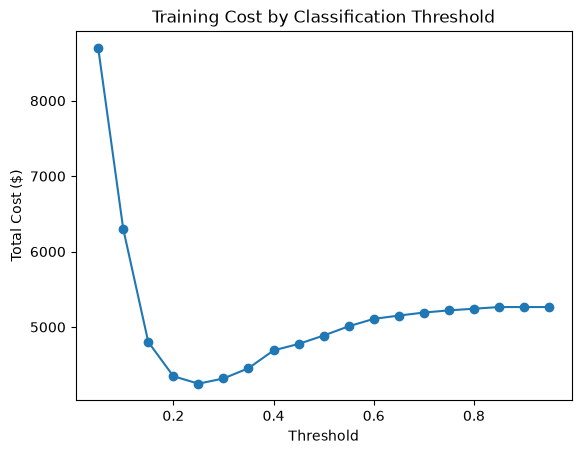

In [4]:
threshold_results = pd.DataFrame(
    json.loads((REPORTS / 'threshold_results.json').read_text())
)
ax = threshold_results.plot(
    x='threshold', y='cost', marker='o', legend=False
)
ax.set_title('Training Cost by Classification Threshold')
ax.set_xlabel('Threshold')
ax.set_ylabel('Total Cost ($)')
plt.show()

## 4. Final Test Evaluation

In [5]:
metrics = json.loads((REPORTS / 'metrics.json').read_text())
pd.Series({
    key: metrics[key]
    for key in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
}).to_frame('value').round(4)

,value
accuracy,0.8360
precision,0.4706
recall,0.4103
f1,0.4384
roc_auc,0.7742


In [6]:
cm = pd.DataFrame(
    metrics['confusion_matrix'],
    index=['Actual On Time', 'Actual Late'],
    columns=['Predicted On Time', 'Predicted Late'],
)
cm

,Predicted On Time,Predicted Late
Actual On Time,579,54
Actual Late,69,48


## 5. Business Cost Comparison

In [7]:
costs = pd.Series(metrics['costs'], name='Cost ($)')
costs.to_frame()

,Cost ($)
flag_none,1755
flag_all,3000
model,1443


## 6. Recommendation

Deploy the tuned logistic regression pipeline as a limited pilot using a 0.25 classification threshold. On the held-out test set, the model policy costs $1,443, compared with $1,755 when flagging no orders and $3,000 when flagging every order. This represents a 17.8% reduction relative to flagging none.

The model uses only features assumed available at order placement. We exclude order_id, prep_minutes, and customer_rating to avoid identifiers and unavailable or leakage-prone information. Courier experience and vehicle type are assumed known at prediction time.

The model detects only 41.0% of late orders. Results come from synthetic data, so operational performance may differ. Monitor costs, recall, and data drift before considering wider deployment.